# Digital holography

A hologram records the interference of the wave scattered by an object, $O$,
with a known reference wave $R$. A camera only measures intensities, but the
cross terms of

$$H = |O + R|^2 = \underbrace{|O|^2 + |R|^2}_{\text{zero order}}
+ \underbrace{O\,R^*}_{+1\ \text{(object)}} + \underbrace{O^*R}_{-1\ \text{(twin)}}$$

carry the full complex field $O$. *Digital* holography records $H$ on a
camera and does the rest numerically: the object term is extracted
(reconstruction), propagated back to the object (refocusing, at any
distance, after the fact), and its phase gives the optical thickness of the
sample (quantitative phase imaging, as in digital holographic microscopy).

`pyoptics.holography` offers:

| Function | Purpose |
|---|---|
| `hologram()`, `phase_shifted_holograms()`, `reference_wave()` | record off-axis and in-line holograms |
| `off_axis_angle_range()`, `max_object_bandwidth()` | sampling condition for the reference angle |
| `reconstruct_off_axis()`, `find_carrier()` | single-shot reconstruction by sideband filtering |
| `reconstruct_phase_shifting()` | in-line (or off-axis) phase-shifting holography |
| `reconstruct_gabor()` | in-line Gabor holography with iterative twin image suppression |
| `suppress_zero_order()` | remove $\lvert O\rvert^2 + \lvert R\rvert^2$ |
| `refocus()`, `focus_metric()`, `autofocus()` | numerical refocusing and focus search |
| `quantitative_phase()`, `remove_tilt()`, `optical_path_difference()` | unwrapped phase maps (via `pyoptics.unwrap`) |

**Conventions.** Fields vary as $e^{i(\mathbf{k}\cdot\mathbf{r} - \omega t)}$.
The reference tilted by $(\theta_x, \theta_y)$ is
$R = A\,e^{i(k_{cx}x + k_{cy}y)}$ with the carrier
$\mathbf{k}_c = k(\sin\theta_x, \sin\theta_y)$, so in the spectrum
`FT(H)` the object order $OR^*$ sits at $-\mathbf{k}_c$ and the twin at
$+\mathbf{k}_c$. Propagation by $z > 0$ multiplies each plane wave by
$e^{+ik_z z}$: the object at the distance $d$ in front of the camera is
brought back into focus with `refocus(O, x, y, -d, ...)`. All lengths are in
micrometres.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from pyoptics import holography as holo
from pyoptics.fft import FT, inv_FT
from pyoptics.interferometry import phase_shifts
from pyoptics.processing import CameraNoiser, Scaler
from pyoptics.unwrap import wrap
from pyoptics.utils import grid2d, freq_grid

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})

wl = 0.633                 # HeNe, um
k = 2*np.pi/wl
N, dx = 512, 0.4           # camera pixels, pitch in object space (um)
L = N*dx
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
K_x, K_y = freq_grid(x, y)
extent = (x[0], x[-1], y[0], y[-1])
k_extent = (K_x[0, 0], K_x[0, -1], K_y[0, 0], K_y[-1, 0])
d = 150.0                  # object-camera distance


def show(ax, img, title, cmap="viridis", ext=extent, colorbar=True, **kwargs):
    im = ax.imshow(img, extent=ext, cmap=cmap, **kwargs)
    ax.set_title(title)
    if colorbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def log_spectrum(H):
    S = np.abs(FT(H - np.mean(H)))
    return np.log10(S/S.max() + 1e-7)


def band_limit(field, B):
    return inv_FT(FT(field)*(K_x**2 + K_y**2 <= B**2))


def propagate(field, z):
    return holo.refocus(field, x, y, z, wl)

## 1. The object and its hologram

The test object combines what a holographic microscope looks at: a few
"cells" (pure phase objects of up to $6\pi$, i.e. thicker than one wave of
optical path), and an absorbing bar target (a USAF-like amplitude object).
The illumination is a broad beam with soft edges, so that diffraction at the
window boundary does not interfere with what follows. The object is band
limited to the numerical aperture $\mathrm{NA} = 0.15$ of the (imagined)
microscope objective, its bandwidth is $B = k\,\mathrm{NA}$.

The camera sits at $d = 150\,\mu$m behind the object plane, so the recorded
object wave is a defocused, unrecognizable diffraction pattern.

bandwidth B = 1.489 rad/um, max. bandwidth for this pitch: 1.963 rad/um
reference angle range 26.74° ... 39.89°, using 33.31°


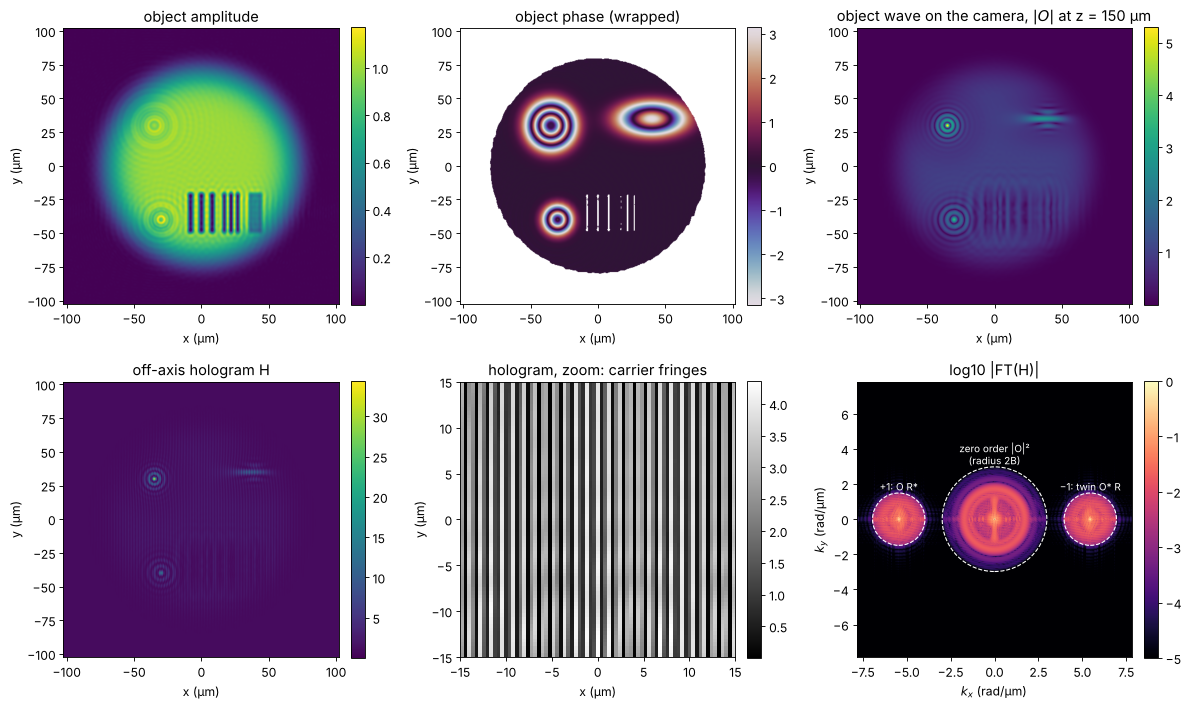

In [2]:
NA = 0.15
B = k*NA

illumination = np.exp(-((X**2 + Y**2)/72**2)**4)
cells = (6*np.pi*np.exp(-((X + 35)**2 + (Y - 30)**2)/14**2)
         + 3*np.pi*np.exp(-(((X - 40)/22)**2 + ((Y - 35)/11)**2))
         + 4*np.pi*np.exp(-((X + 30)**2 + (Y + 40)**2)/9**2))
bars = np.ones_like(X)
for i, (w, x0) in enumerate([(4.0, -8), (2.5, 17), (1.6, 37)]):
    for j in range(3):
        xc = x0 + 2*j*w
        bars[(np.abs(X - xc) < w/2) & (np.abs(Y + 35) < 15)] = 0.15
obj = band_limit(illumination*bars*np.exp(1j*cells), B)
cell_phase = cells    # true phase (used for comparisons)

O = propagate(obj, d)                  # object wave on the camera

theta_min, theta_max = holo.off_axis_angle_range(B, x, y, wl)
theta = 0.5*(theta_min + theta_max)
print(f"bandwidth B = {B:.3f} rad/um, max. bandwidth for this pitch: {holo.max_object_bandwidth(x, y):.3f} rad/um")
print(f"reference angle range {np.degrees(theta_min):.2f}° ... {np.degrees(theta_max):.2f}°, using {np.degrees(theta):.2f}°")

H = holo.hologram(O, x, y, wl, ref_angle=(theta, 0.0))

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
show(axes[0, 0], np.abs(obj), "object amplitude")
lit = np.abs(obj) > 0.1
show(axes[0, 1], np.where(lit, np.angle(obj), np.nan), "object phase (wrapped)", cmap="twilight")
show(axes[0, 2], np.abs(O), f"object wave on the camera, $|O|$ at z = {d:g} µm")
show(axes[1, 0], H, "off-axis hologram H")
zoom = (np.abs(x) < 15)
show(axes[1, 1], H[np.ix_(zoom, zoom)], "hologram, zoom: carrier fringes",
     ext=(-15, 15, -15, 15), cmap="gray")
im = show(axes[1, 2], log_spectrum(H), "log10 |FT(H)|", cmap="magma", ext=k_extent, vmin=-5)
k_c = k*np.sin(theta)
for center, r, label in [((0, 0), 2*B, "zero order |O|²\n(radius 2B)"),
                         ((-k_c, 0), B, "+1: O R*"), ((k_c, 0), B, "−1: twin O* R")]:
    axes[1, 2].add_patch(Circle(center, r, fill=False, color="w", ls="--"))
    axes[1, 2].annotate(label, (center[0], center[1] + r + 0.15), color="w", ha="center", fontsize=9)
axes[1, 2].set_xlabel("$k_x$ (rad/µm)"); axes[1, 2].set_ylabel("$k_y$ (rad/µm)")
for ax in axes.flat[:5]:
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)")
plt.tight_layout()

The spectrum shows the three orders: the zero order at $k = 0$ (the
autocorrelation $|O|^2$ has twice the bandwidth of $O$, radius $2B$, plus the
DC peak of $|R|^2$), the object at $-k_c$ and its complex conjugate twin at
$+k_c$, both of radius $B$.

## 2. The sampling condition

The orders have to be separated, $|k_c| \ge 3B$, and the object order has to
fit below the camera's Nyquist frequency, $|k_c| + B \le \pi/\Delta x$. Both
hold only for $B \le \pi/(4\Delta x)$: an off-axis hologram can use at most a
quarter of the camera's bandwidth for the object (along one axis). This is
the price of single-shot reconstruction. The figure shows the window of
usable reference angles against the object NA for our pixel pitch, and what
happens below the minimum angle: the zero order overlaps the object order
and leaks into the reconstruction.

/home/claude/pyoptics/pyoptics/holography.py:451: UserWarning: The window radius exceeds half the carrier: the zero order leaks into the reconstruction.
  warnings.warn("The window radius exceeds half the carrier: the zero "


rms error of the refocused object: θ = 33.3°: 4.1e-03, θ = 13.9°: 1.2e-01


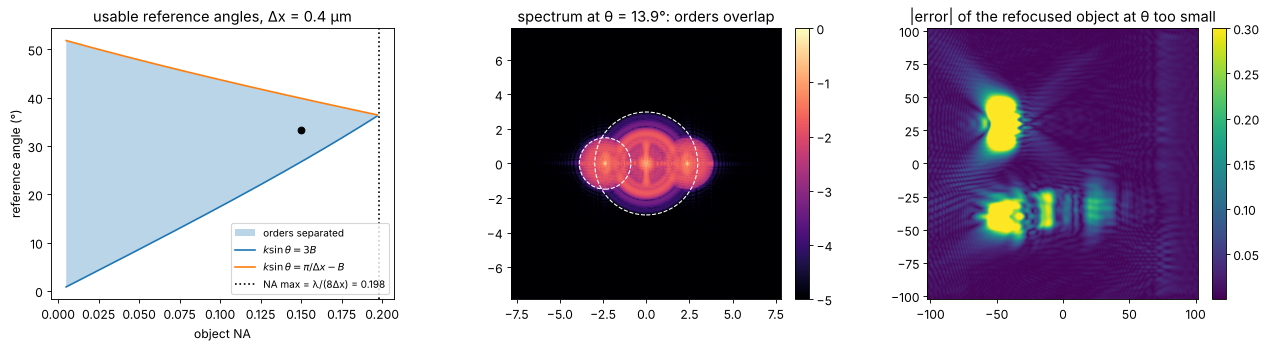

In [3]:
NAs = np.linspace(0.005, 0.25, 200)
ranges = []
for na in NAs:
    try:
        ranges.append(np.degrees(holo.off_axis_angle_range(k*na, x, y, wl)))
    except ValueError:
        ranges.append((np.nan, np.nan))
ranges = np.array(ranges)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ax = axes[0]
ax.fill_between(NAs, ranges[:, 0], ranges[:, 1], alpha=0.3, label="orders separated")
ax.plot(NAs, ranges[:, 0], "C0", label=r"$k\sin\theta = 3B$")
ax.plot(NAs, ranges[:, 1], "C1", label=r"$k\sin\theta = \pi/\Delta x - B$")
NA_max = holo.max_object_bandwidth(x, y)/k
ax.axvline(NA_max, color="k", ls=":", label=f"NA max = λ/(8Δx) = {NA_max:.3f}")
ax.plot(NA, np.degrees(theta), "ko")
ax.set_xlabel("object NA"); ax.set_ylabel("reference angle (°)")
ax.set_title(f"usable reference angles, Δx = {dx} µm"); ax.legend(fontsize=9)

theta_small = np.arcsin(1.6*B/k)   # carrier only 1.6 B: overlap
H_small = holo.hologram(O, x, y, wl, ref_angle=(theta_small, 0.0))
show(axes[1], log_spectrum(H_small), f"spectrum at θ = {np.degrees(theta_small):.1f}°: orders overlap",
     cmap="magma", ext=k_extent, vmin=-5)
for center, r in [((0, 0), 2*B), ((-1.6*B, 0), B)]:
    axes[1].add_patch(Circle(center, r, fill=False, color="w", ls="--"))

rec_good = propagate(holo.reconstruct_off_axis(H, x, y, wl, ref_angle=(theta, 0), radius=B,
                                               window="circle"), -d)
rec_small = propagate(holo.reconstruct_off_axis(H_small, x, y, wl, ref_angle=(theta_small, 0),
                                                radius=B, window="circle"), -d)
show(axes[2], np.abs(rec_small - obj), "|error| of the refocused object at θ too small", vmax=0.3)
print(f"rms error of the refocused object: θ = {np.degrees(theta):.1f}°: {np.sqrt(np.mean(np.abs(rec_good - obj)**2)):.1e}, "
      f"θ = {np.degrees(theta_small):.1f}°: {np.sqrt(np.mean(np.abs(rec_small - obj)**2)):.1e}")
plt.tight_layout()

## 3. Off-axis reconstruction and numerical refocusing

`reconstruct_off_axis()` multiplies the hologram by the numerical reference
$R$ (this is the "reconstruction wave" of classical holography). The object
term $O|R|^2$ moves to $k = 0$, the zero order to $+k_c$ and the twin to
$+2k_c$; a window of radius $B$ around the origin then keeps only the object.
The result is the complex object wave **in the camera plane**: still out of
focus. `refocus()` propagates it by $-d$ (band-limited angular spectrum with
zero padding), and the object reappears with amplitude and phase. The
reconstruction agrees with the true object to the 1e-3 level; what is left
comes from the spectral leakage of the window edges.

max |error| of O in the camera plane: 5.5e-02, of the refocused object: 1.8e-02


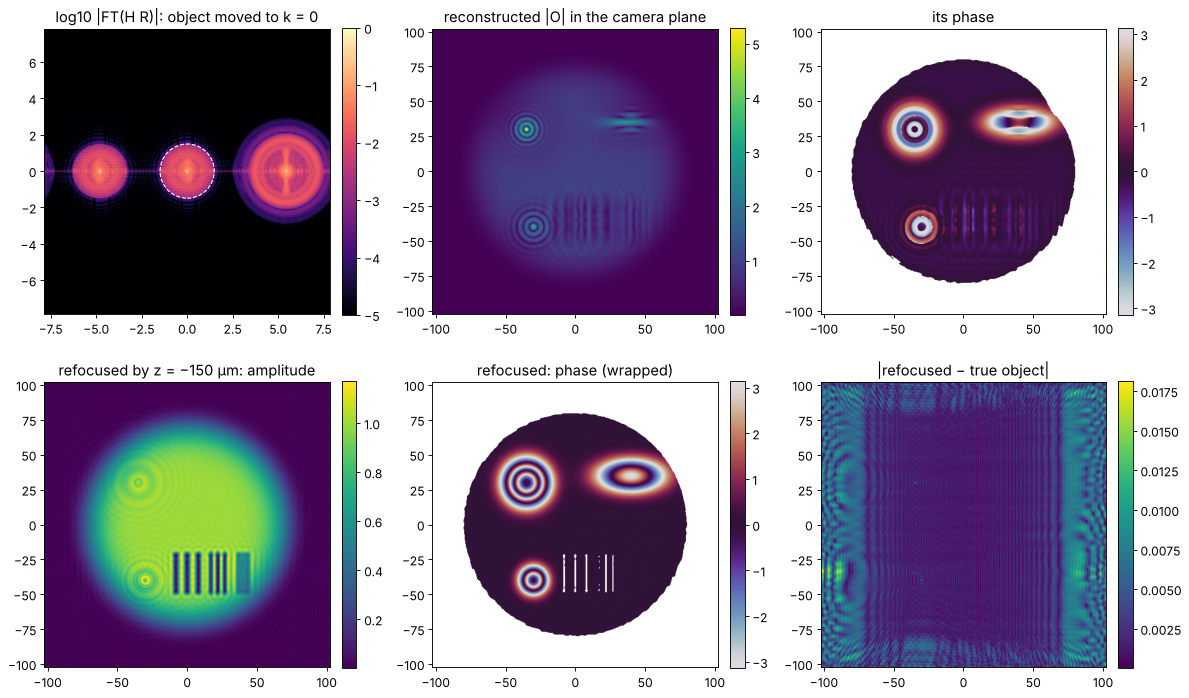

In [4]:
O_rec, spectrum, W = holo.reconstruct_off_axis(H, x, y, wl, ref_angle=(theta, 0.0), radius=B,
                                               window="circle", return_spectrum=True)
obj_rec = holo.refocus(O_rec, x, y, -d, wl)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
S = np.abs(spectrum)
show(axes[0, 0], np.log10(S/S.max() + 1e-7), "log10 |FT(H R)|: object moved to k = 0",
     cmap="magma", ext=k_extent, vmin=-5)
axes[0, 0].add_patch(Circle((0, 0), B, fill=False, color="w", ls="--"))
show(axes[0, 1], np.abs(O_rec), "reconstructed |O| in the camera plane")
show(axes[0, 2], np.where(np.abs(O_rec) > 0.1, np.angle(O_rec), np.nan), "its phase", cmap="twilight")
show(axes[1, 0], np.abs(obj_rec), f"refocused by z = −{d:g} µm: amplitude")
show(axes[1, 1], np.where(lit, np.angle(obj_rec), np.nan), "refocused: phase (wrapped)", cmap="twilight")
show(axes[1, 2], np.abs(obj_rec - obj), "|refocused − true object|")
plt.tight_layout()
print(f"max |error| of O in the camera plane: {np.max(np.abs(O_rec - O)):.1e}, "
      f"of the refocused object: {np.max(np.abs(obj_rec - obj)):.1e}")

**Sign of z, and the twin.** Refocusing the twin $O^*$ instead of $O$ (as one
gets when picking the wrong sideband) gives a focused image at $+d$, not
$-d$, with the complex conjugate (negative) phase. Because the spectrum of a
real hologram is symmetric, `find_carrier()` cannot tell the sidebands apart;
it returns the carrier with $k_x > 0$, which is the right one for references
tilted towards $+x$. Pass the known reference angle whenever possible.

carrier found: (5.45266, -0.00438) rad/um, true: (5.45171, 0)


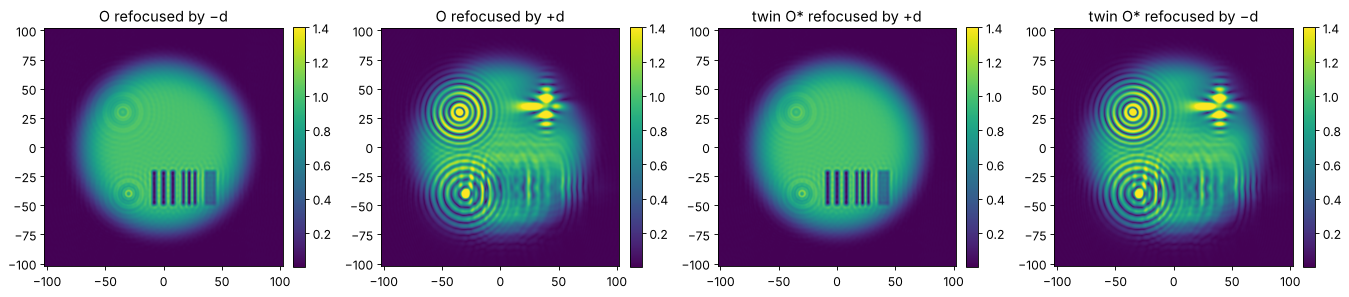

In [5]:
k_found = holo.find_carrier(H, x, y)
print(f"carrier found: ({k_found[0]:.5f}, {k_found[1]:.5f}) rad/um, true: ({k_c:.5f}, 0)")
twin = np.conj(O_rec)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (field, z, title) in zip(axes, [(O_rec, -d, "O refocused by −d"), (O_rec, +d, "O refocused by +d"),
                                         (twin, +d, "twin O* refocused by +d"), (twin, -d, "twin O* refocused by −d")]):
    show(ax, np.abs(holo.refocus(field, x, y, z, wl)), title, vmax=1.4)
plt.tight_layout()

## 4. Window shape and resolution

The filter window decides how much of the object spectrum survives. A hard
circular window of radius $B$ keeps everything the object has, but rings if
the object spectrum is not really zero at the edge (and it leaks the
neighbouring orders in with sharp edges). Smooth windows (Tukey, Hann,
Gaussian) suppress ringing and noise at the cost of resolution: they act as
an apodized pupil. Without knowledge of $B$, `reconstruct_off_axis()` uses
the largest safe radius $|k_c|/3$. The profiles go through the bar target
(bars of 4, 2.5 and 1.6 µm); the right panel shows the reconstruction error
against the window radius.

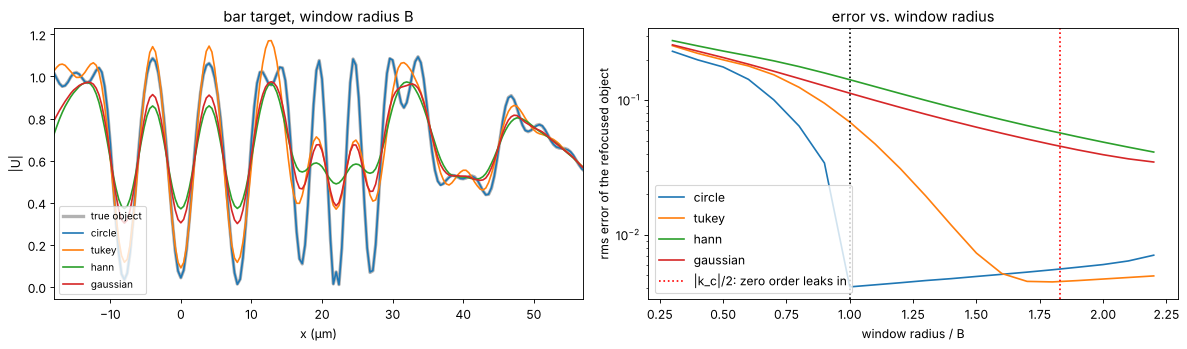

In [6]:
row = np.argmin(np.abs(y + 35))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(x, np.abs(obj[row]), "k", lw=3, alpha=0.3, label="true object")
for window in ("circle", "tukey", "hann", "gaussian"):
    rec = propagate(holo.reconstruct_off_axis(H, x, y, wl, ref_angle=(theta, 0), radius=B,
                                              window=window), -d)
    axes[0].plot(x, np.abs(rec[row]), label=window)
axes[0].set_xlim(-18, 57); axes[0].set_xlabel("x (µm)"); axes[0].set_ylabel("|U|")
axes[0].set_title("bar target, window radius B"); axes[0].legend(loc="lower left", fontsize=9)

radii = np.linspace(0.3, 2.2, 20)*B
for window in ("circle", "tukey", "hann", "gaussian"):
    errs = []
    for r in radii:
        with np.errstate(all="ignore"):
            import warnings
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                rec = propagate(holo.reconstruct_off_axis(H, x, y, wl, ref_angle=(theta, 0),
                                                          radius=r, window=window), -d)
        errs.append(np.sqrt(np.mean(np.abs(rec - obj)**2)))
    axes[1].semilogy(radii/B, errs, label=window)
axes[1].axvline(1, color="k", ls=":")
axes[1].axvline(k_c/2/B, color="r", ls=":", label="|k_c|/2: zero order leaks in")
axes[1].set_xlabel("window radius / B"); axes[1].set_ylabel("rms error of the refocused object")
axes[1].legend(); axes[1].set_title("error vs. window radius")
plt.tight_layout()

## 5. Zero-order suppression

The zero order is usually the strongest part of the hologram. Removing it
before filtering relaxes the separation condition (the object then only
needs to avoid its twin). `suppress_zero_order()` offers three ways:
subtracting the mean (only the DC peak; `reconstruct_off_axis()` does this
by default), a high-pass filter (removes slowly varying $|O|^2 + |R|^2$) and
subtracting separately recorded intensities of reference and object (exact,
at the cost of two extra exposures).

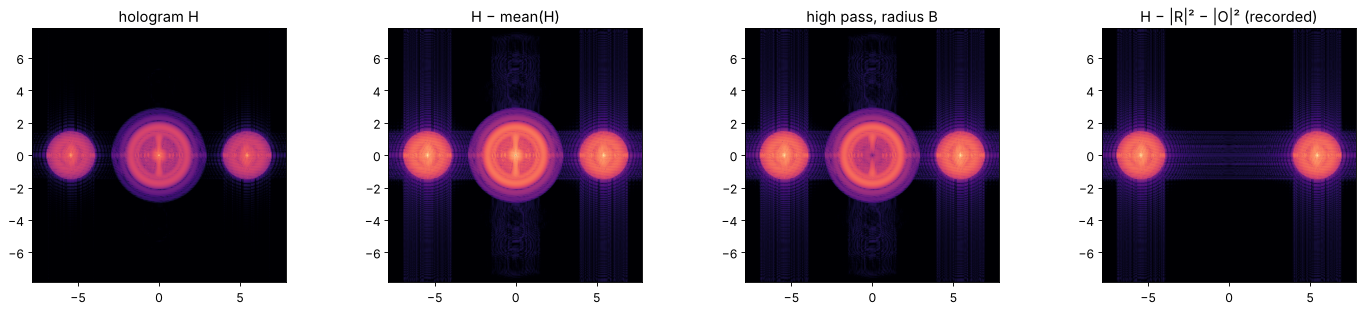

In [7]:
I_ref = np.abs(holo.reference_wave(x, y, wl, (theta, 0)))**2
variants = [("hologram H", H),
            ("H − mean(H)", holo.suppress_zero_order(H)),
            ("high pass, radius B", holo.suppress_zero_order(H, x, y, "highpass", radius=B)),
            ("H − |R|² − |O|² (recorded)", holo.suppress_zero_order(H, method="recorded",
                                                                  I_ref=I_ref, I_obj=np.abs(O)**2))]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (title, Hv) in zip(axes, variants):
    S = np.abs(FT(Hv))
    show(ax, np.log10(S/S.max() + 1e-7), title, cmap="magma", ext=k_extent, vmin=-6, colorbar=False)
plt.tight_layout()

## 6. Autofocus

In practice the distance $d$ is rarely known to better than a few
micrometres. `autofocus()` refocuses to a range of distances and evaluates a
sharpness metric of the amplitude in each plane. For amplitude objects the
metrics peak in focus: there the image has the highest contrast. Pure phase
objects are the opposite: in focus their amplitude is uniform and the metrics
have a *minimum*, while the phase turns into intensity contrast on both
sides (with opposite signs). Hence the `object_type` argument. The metrics
are evaluated in a region of interest (`mask`) around the bar target and
around the cells.

The bar target is found exactly by all metrics. The cells are strong phase
objects (up to $6\pi$), for which the minimum is broad and the
weak-object picture behind it no longer holds: the gradient metric still
finds the focus within a few micrometres, variance and Tamura coefficient
are biased by about 10 µm, and the Laplacian, which weighs the finest
structures, has no useful minimum here. For phase objects, prefer the
gradient metric, a narrow region of interest and a search range close to
the expected focus.

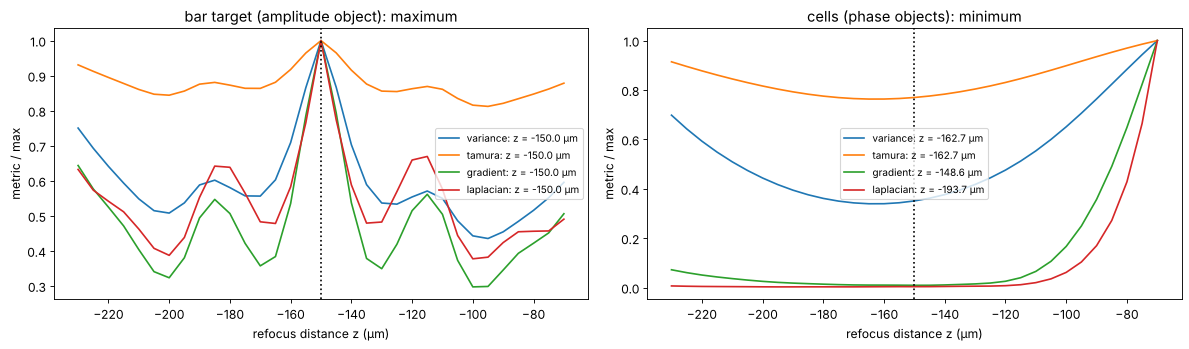

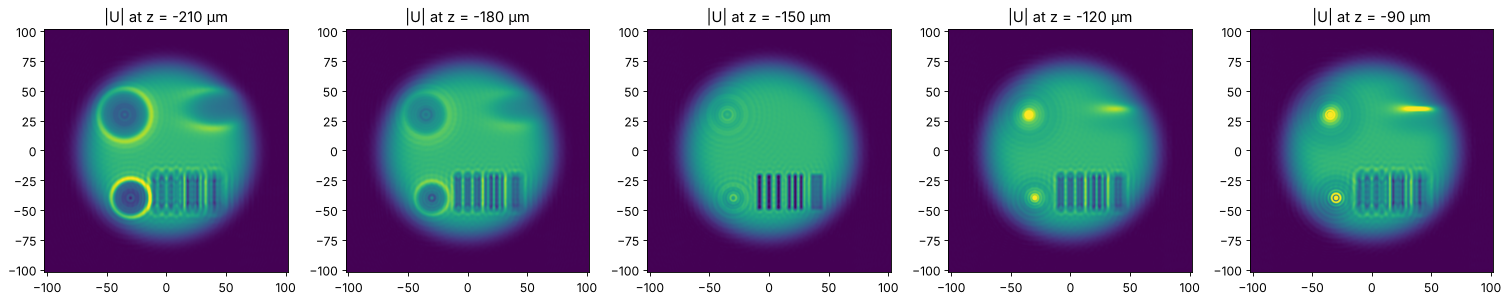

In [8]:
z_range = np.linspace(-230, -70, 33)
roi_bars = (np.abs(X - 17) < 35) & (np.abs(Y + 35) < 25)
roi_cells = (Y > 10) & (Y < 55) & (np.abs(X) < 65)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for metric in holo.focus_metrics:
    z_best, values = holo.autofocus(O_rec, x, y, z_range, wl, metric=metric, mask=roi_bars)
    axes[0].plot(z_range, values/values.max(), label=f"{metric}: z = {z_best:.1f} µm")
    # the cells (phase objects): metric minimal in focus
    z_best, values = holo.autofocus(O_rec, x, y, z_range, wl, metric=metric, mask=roi_cells,
                                    object_type="phase")
    axes[1].plot(z_range, values/values.max(), label=f"{metric}: z = {z_best:.1f} µm")
for ax, title in zip(axes, ["bar target (amplitude object): maximum", "cells (phase objects): minimum"]):
    ax.axvline(-d, color="k", ls=":")
    ax.set_xlabel("refocus distance z (µm)"); ax.set_ylabel("metric / max"); ax.set_title(title)
    ax.legend(fontsize=9)
plt.tight_layout()

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, z in zip(axes, [-210, -180, -150, -120, -90]):
    show(ax, np.abs(holo.refocus(O_rec, x, y, z, wl)), f"|U| at z = {z} µm", colorbar=False, vmax=1.5)
plt.tight_layout()

## 7. Quantitative phase

The phase of the refocused field is the optical path difference of the
sample, $\varphi = k\,\mathrm{OPD}$. Two practical problems:

* the cells are thicker than one wave, so the phase is wrapped and has to be
  unwrapped (`pyoptics.unwrap`, quality guided by default);
* the reconstruction carries the aberrations of the object arm (microscope
  objective, cover glass, cuvette) and any error of the carrier (e.g. when
  it is estimated with `find_carrier()`), which show up as tilt and
  curvature of the phase.

The standard remedy in digital holographic microscopy is a second hologram
without the sample: the phase of $U\,U_\mathrm{bg}^*$ is free of everything
common to both. `remove_tilt()` on the sample-free area then fixes the
remaining piston and tilt. Here the object arm adds defocus and astigmatism
(a slightly curved, tilted cover glass), the reference is spherical (a point
source 20 mm away, passed to `reconstruct_off_axis(..., reference=R)`; a
curved reference treated as a plane wave would act as a lens on $O$ and
shift the focus), and the carrier comes from `find_carrier()`. The error
maps compare with the phase of the band-limited object, i.e. what an
NA = 0.15 system can see at all.

The compensation removes the aberrations to the 0.01 rad level. What
remains are the dipoles at the cells: the estimated carrier is off by a
small fraction of a frequency pixel, which tilts the field on the camera,
and refocusing over $d$ turns a tilt $\delta k$ into a lateral shift
$d\,\delta k/k$ of the image. The background is uniform there, so the
compensation cannot see the shift. A known reference angle (or a carrier
fitted more accurately) avoids it.

rms phase error, uncompensated: 3.4e-01 rad = λ/18 of OPD
rms phase error, compensated: 4.4e-02 rad = λ/142 of OPD
carrier error (-8.5e-03, -6.5e-03) rad/µm -> image shift (-129, -98) nm


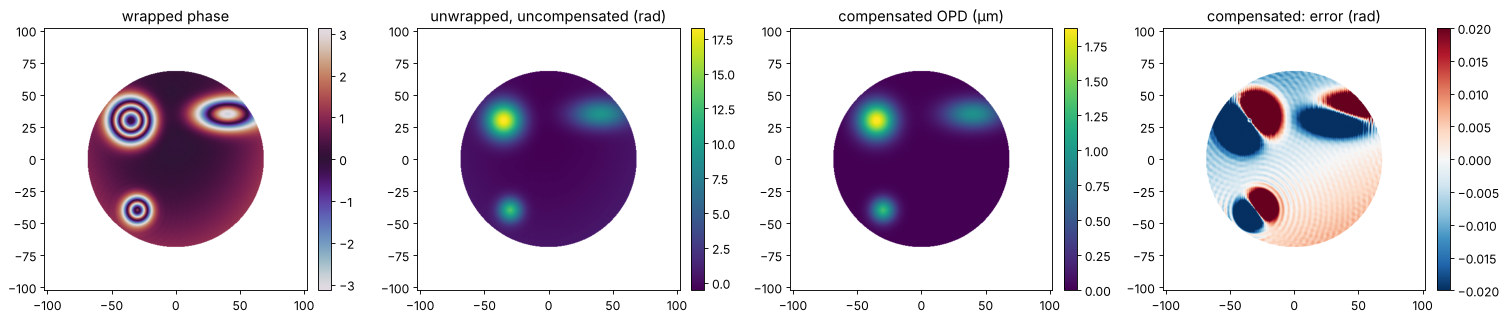

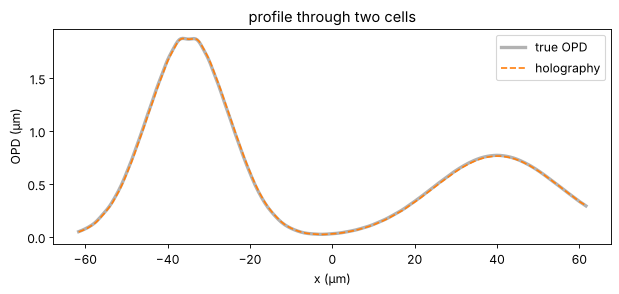

In [9]:
aberration = np.exp(1j*(2e-4*X**2 + 1.2e-4*Y**2 + 0.01*X))      # object arm, common to both holograms
R_curved = holo.reference_wave(x, y, wl, (theta, 0)) * np.exp(1j*k*(X**2 + Y**2)/(2*20e3))
obj_cells = band_limit(illumination*np.exp(1j*cells), B)
H_sample = np.abs(propagate(obj_cells*aberration, d) + R_curved)**2
H_background = np.abs(propagate(band_limit(illumination*aberration + 0j, B), d) + R_curved)**2

carrier = holo.find_carrier(H_sample, x, y)
R_num = R_curved*np.exp(1j*((carrier[0] - k_c)*X + carrier[1]*Y))   # numerical reference with the estimated carrier
reconstruct = lambda H: holo.refocus(holo.reconstruct_off_axis(H, x, y, wl, carrier=carrier, radius=1.2*B,
                                                               reference=R_num), x, y, -d, wl)
U_sample, U_bg = reconstruct(H_sample), reconstruct(H_background)

valid = illumination > 0.5
background = valid & (cells < 0.05)
phase_true = holo.quantitative_phase(obj_cells, mask=valid)   # band-limited truth
phase_true -= np.mean(phase_true[background])
phase_raw = holo.quantitative_phase(U_sample, mask=valid)
phase_raw -= np.mean(phase_raw[background])
phase_comp = holo.quantitative_phase(U_sample, x, y, reference_field=U_bg, mask=valid,
                                     tilt_mask=background)
opd = holo.optical_path_difference(phase_comp, wl)

nan = lambda a: np.where(valid, a, np.nan)
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
show(axes[0], nan(np.angle(U_sample)), "wrapped phase", cmap="twilight")
show(axes[1], nan(phase_raw), "unwrapped, uncompensated (rad)")
show(axes[2], nan(opd), "compensated OPD (µm)")
show(axes[3], nan(phase_comp - phase_true), "compensated: error (rad)", cmap="RdBu_r", vmin=-0.02, vmax=0.02)
plt.tight_layout()

row = np.argmin(np.abs(y - 30))
plt.figure(figsize=(9, 3.5))
plt.plot(x, nan(phase_true)[row]*wl/(2*np.pi), "k", lw=3, alpha=0.3, label="true OPD")
plt.plot(x, nan(opd)[row], "C1--", label="holography")
plt.xlabel("x (µm)"); plt.ylabel("OPD (µm)"); plt.legend(); plt.title("profile through two cells")
in_valid = valid & (illumination > 0.9)
for name, ph in [("uncompensated", phase_raw), ("compensated", phase_comp)]:
    rms = np.sqrt(np.mean((ph - phase_true)[in_valid]**2))
    print(f"rms phase error, {name}: {rms:.1e} rad = λ/{2*np.pi/rms:.0f} of OPD")
dk = np.array(carrier) - np.array([k_c, 0.0])
print(f"carrier error ({dk[0]:.1e}, {dk[1]:.1e}) rad/µm -> image shift ({d*dk[0]/k*1e3:.0f}, {d*dk[1]/k*1e3:.0f}) nm")

## 8. Camera noise

A real hologram is recorded with shot noise and the noise of the camera. We
scale the hologram so that the mean exposure is $\bar n$ photons per pixel
and pass it through `processing.CameraNoiser` (EMVA 1288 model with shot
noise and 5 electrons read noise, no saturation). The phase noise of the reconstruction falls as
$1/\sqrt{\bar n}$; the window removes the noise outside the object band, so
off-axis holography only "sees" the noise in a quarter of the bandwidth.

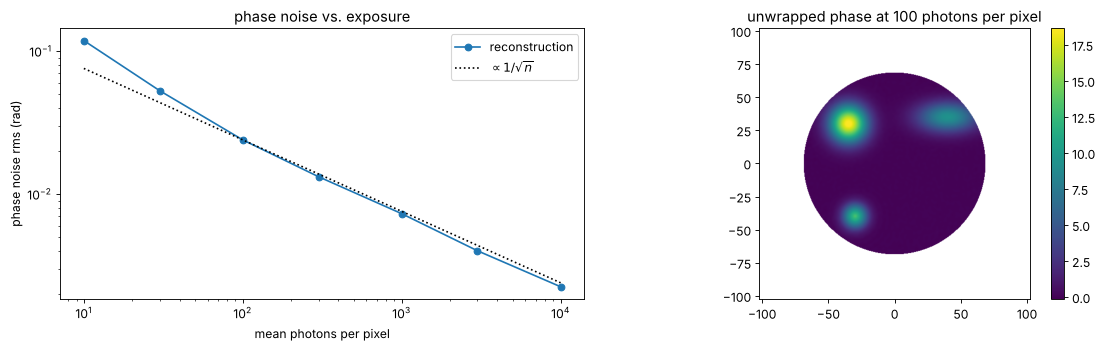

In [10]:
photons = [10, 30, 100, 300, 1000, 3000, 10000]
noise_rms = []
for n_mean in photons:
    scale = n_mean/np.mean(H_sample)
    noiser = CameraNoiser("camera", read_noise=5.0, rng=1)
    H_noisy = noiser(H_sample*scale)/scale
    U = reconstruct(H_noisy)
    phase = holo.quantitative_phase(U, x, y, reference_field=U_bg, mask=valid, tilt_mask=background)
    noise_rms.append(np.sqrt(np.mean((phase - phase_comp)[in_valid]**2)))
    if n_mean == 100:
        phase_100 = phase

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].loglog(photons, noise_rms, "o-", label="reconstruction")
axes[0].loglog(photons, noise_rms[2]*np.sqrt(photons[2]/np.array(photons)), "k:", label=r"$\propto 1/\sqrt{n}$")
axes[0].set_xlabel("mean photons per pixel"); axes[0].set_ylabel("phase noise rms (rad)"); axes[0].legend()
axes[0].set_title("phase noise vs. exposure")
show(axes[1], nan(phase_100), "unwrapped phase at 100 photons per pixel")
plt.tight_layout()

## 9. Phase-shifting holography

With a phase shifter in the reference arm, several holograms with known
shifts $\delta_j$ give $O R^*$ pixel by pixel (least squares, the same
algorithm as `interferometry.psi_n_step()`). Zero order and twin cancel
exactly, so an in-line reference works and the object may use the camera's
**full** bandwidth instead of a quarter. Here the object is band limited to
NA = 0.6, four times the off-axis limit; four in-line frames reconstruct it
to rounding error, the off-axis hologram of the same object cannot.

max |error| in the camera plane: 2.8e-15


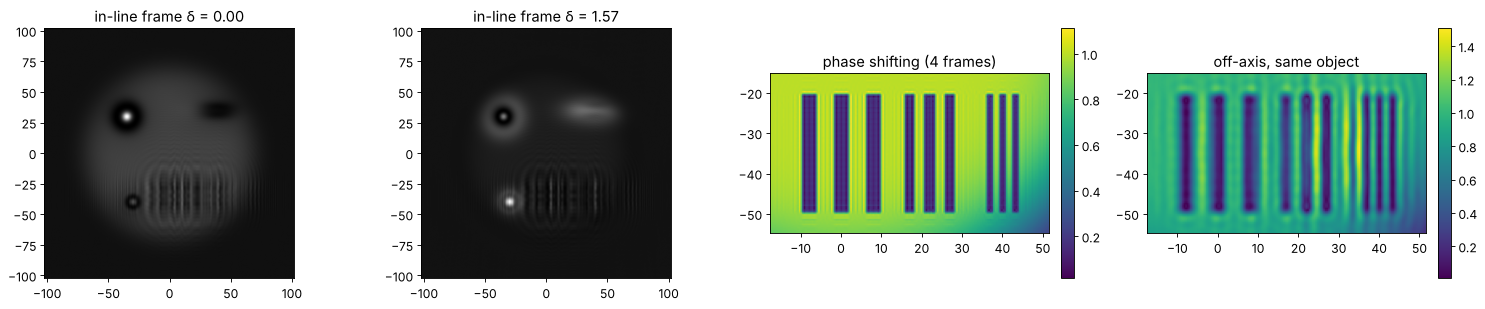

In [11]:
B_wide = 0.95*np.pi/dx                          # almost the full Nyquist band
obj_wide = band_limit(illumination*bars*np.exp(1j*cells/3), B_wide)
O_wide = propagate(obj_wide, d)
shifts = phase_shifts(4)
frames = holo.phase_shifted_holograms(O_wide, x, y, wl, shifts)     # in-line
O_psh = holo.reconstruct_phase_shifting(frames, shifts)
obj_psh = holo.refocus(O_psh, x, y, -d, wl)
print(f"max |error| in the camera plane: {np.max(np.abs(O_psh - O_wide)):.1e}")

with np.errstate(all="ignore"):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        H_wide = holo.hologram(O_wide, x, y, wl, ref_angle=(theta_max, 0))
        obj_oa = holo.refocus(holo.reconstruct_off_axis(H_wide, x, y, wl, ref_angle=(theta_max, 0)),
                              x, y, -d, wl)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, j in zip(axes[:2], (0, 1)):
    show(ax, frames[..., j], f"in-line frame δ = {shifts[j]:.2f}", cmap="gray", colorbar=False)
zoom = (x > -18) & (x < 52)
zy = (y > -55) & (y < -15)
ext_zoom = (x[zoom][0], x[zoom][-1], y[zy][0], y[zy][-1])
show(axes[2], np.abs(obj_psh)[np.ix_(zy, zoom)], "phase shifting (4 frames)", ext=ext_zoom)
show(axes[3], np.abs(obj_oa)[np.ix_(zy, zoom)], "off-axis, same object", ext=ext_zoom)
plt.tight_layout()

## 10. Gabor (in-line) holography and the twin image

Gabor's original scheme needs no reference arm at all: a plane wave
illuminates a mostly transparent object, the unscattered light acts as the
reference. Back-propagating the hologram brings the object into focus, but
the twin $O^*$ ends up defocused by $2d$ on top of it, a ring pattern
around every feature. `reconstruct_gabor()` suppresses it iteratively: in the
object plane the transmission may not exceed 1 (absorbing object) and equals
1 outside a support; in the camera plane the measured amplitude
$\sqrt{H}$ is imposed (Latychevskaia and Fink 2007). The illumination is a
plane wave filling the whole window, which is periodic, so we propagate
without zero padding (`pad_factor=1`); padding would cut the plane wave at
the window edge and add edge diffraction.

rms error vs. the true object: plain 0.209, iterated 0.045


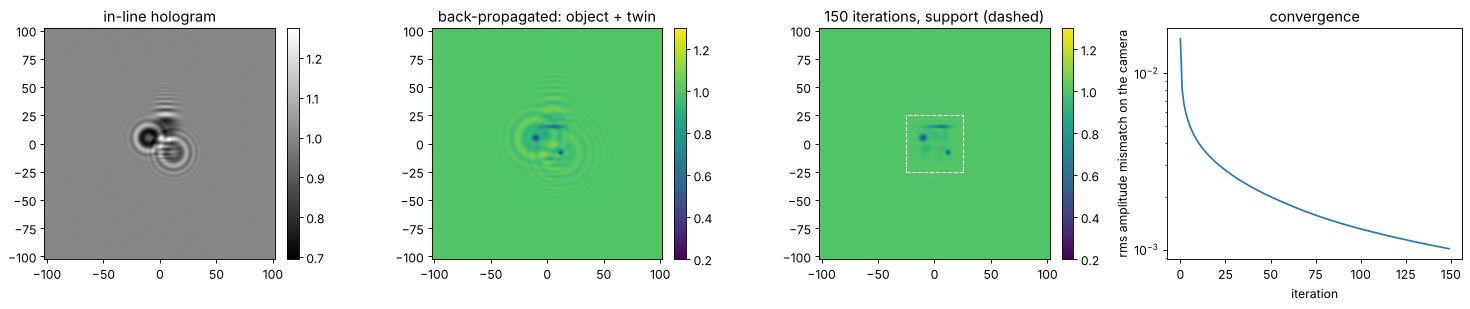

In [12]:
particles = 1 - 0.7*np.exp(-((X + 10)**2 + (Y - 5)**2)/3**2) - 0.6*np.exp(-((X - 12)**2 + (Y + 8)**2)/2**2) \
              - 0.5*np.exp(-(((X - 5)/8)**2 + ((Y - 15)/1.5)**2))
particles = band_limit(particles + 0j, 0.8*np.pi/dx)
# a plane wave is periodic in the window: propagate without zero padding
H_gabor = np.abs(holo.refocus(particles, x, y, d, wl, pad_factor=1))**2
support = (np.abs(X) < 25) & (np.abs(Y) < 25)

plain = holo.reconstruct_gabor(H_gabor, x, y, d, wl, pad_factor=1)
iterated, errors = holo.reconstruct_gabor(H_gabor, x, y, d, wl, n_iter=150, support=support,
                                          pad_factor=1, return_errors=True)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
show(axes[0], H_gabor, "in-line hologram", cmap="gray")
show(axes[1], np.abs(plain), "back-propagated: object + twin", vmin=0.2, vmax=1.3)
show(axes[2], np.abs(iterated), "150 iterations, support (dashed)", vmin=0.2, vmax=1.3)
axes[2].add_patch(plt.Rectangle((-25, -25), 50, 50, fill=False, ls="--", color="w"))
axes[3].semilogy(errors)
axes[3].set_xlabel("iteration"); axes[3].set_ylabel("rms amplitude mismatch on the camera")
axes[3].set_title("convergence")
plt.tight_layout()
c = (np.abs(X) < 60) & (np.abs(Y) < 60)
print(f"rms error vs. the true object: plain {np.sqrt(np.mean(np.abs(plain - particles)[c]**2)):.3f}, "
      f"iterated {np.sqrt(np.mean(np.abs(iterated - particles)[c]**2)):.3f}")

## Summary

* **Off-axis** holography reconstructs the complex field from a single
  frame by sideband filtering, but the object may only use a quarter of the
  camera bandwidth: choose the reference angle with `off_axis_angle_range()`
  ($3B \le k\sin\theta \le \pi/\Delta x - B$) and the window radius $\approx B$.
  Smooth windows trade resolution for less ringing.
* **Phase shifting** removes zero order and twin pixel by pixel, works in
  line and uses the full bandwidth, at the cost of several frames and a
  stable setup.
* **Gabor** holography is the simplest setup; its twin image can be reduced
  iteratively with support and absorption constraints.
* Refocus with `refocus(O, x, y, -d, wl)`: positive z propagates away from
  the object. If the focus distance is unknown, `autofocus()` finds it;
  amplitude objects maximize the metrics, phase objects minimize them.
* For quantitative phase, compensate the setup with a background hologram
  (or `remove_tilt()` on a sample-free region) and unwrap with
  `pyoptics.unwrap`.